              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  
(13320, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  obj

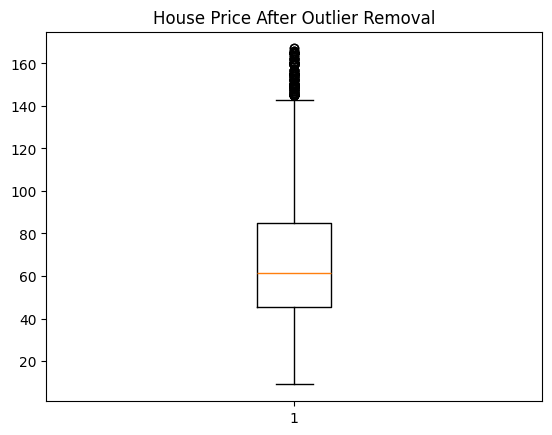

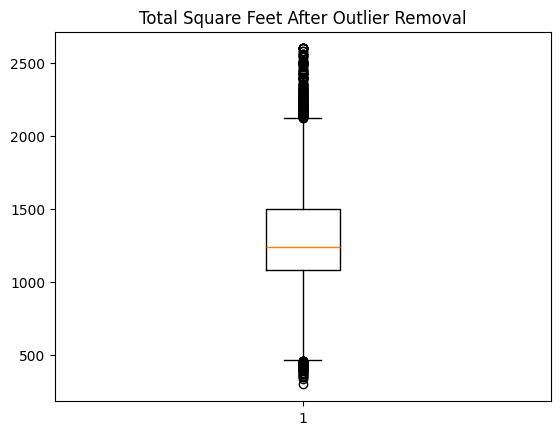

Data wrangling completed successfully.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# 1. Import dataset and clean column names
df = pd.read_csv("Bengaluru_House_Data.csv")

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.head())
print(df.shape)
print(df.info())

# 2. Handle missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert total_sqft into numeric values
def convert_sqft(x):
    x = str(x).strip()

    # Handle ranges such as 2100 - 2850
    if "-" in x:
        try:
            a, b = x.split("-")
            return (float(a) + float(b)) / 2
        except:
            return np.nan

    # Handle common area units
    try:
        value = float(x)
        return value
    except:
        match = re.search(r"\d+\.?\d*", x)
        if not match:
            return np.nan

        value = float(match.group())

        if "meter" in x.lower():
            return value * 10.7639
        elif "yard" in x.lower():
            return value * 9
        else:
            return np.nan

df["total_sqft"] = df["total_sqft"].apply(convert_sqft)

# Convert numeric columns
for col in ["bath", "balcony", "price"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numerical values with median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# 3. Data merging
# No additional dataset is provided, so merging is not applicable.

# 4. Filter and subset the data

# Extract BHK from size
df["bhk"] = df["size"].str.extract(r"(\d+)").astype(float)

# Remove the original size column
df = df.drop(columns=["size"])

# Keep properties with reasonable area per bedroom
df = df[df["total_sqft"] / df["bhk"] >= 300]

# Group locations with fewer than 10 properties as 'other'
df["location"] = df["location"].str.strip()

location_counts = df["location"].value_counts()

rare_locations = location_counts[location_counts < 10].index

df["location"] = df["location"].replace(rare_locations, "other")

print("Filtered dataset shape:", df.shape)

# 5. Encode categorical variables

# Remove columns not needed for this analysis
df = df.drop(columns=["society"], errors="ignore")

# One-hot encode categorical columns
df_encoded = pd.get_dummies(
    df,
    columns=["area_type", "availability", "location"],
    drop_first=True,
    dtype=int
)

print("Encoded dataset:")
print(df_encoded.head())

# 6. Aggregate summary statistics

# Calculate price per square foot
df["price_per_sqft"] = df["price"] * 100000 / df["total_sqft"]

print("Overall sales statistics:")
print(df["price"].describe())

print("Average price by location:")
print(
    df.groupby("location")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print("Average price by property type:")
print(df.groupby("area_type")["price"].mean())

print("Average price per square foot by location:")
print(
    df.groupby("location")["price_per_sqft"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# 7. Identify and handle outliers using IQR

def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[
        (data[column] >= lower) &
        (data[column] <= upper)
    ]

print("Shape before outlier removal:", df.shape)

for col in ["total_sqft", "bath", "bhk", "price", "price_per_sqft"]:
    df = remove_outliers(df, col)

print("Shape after outlier removal:", df.shape)

# Visualize outliers after cleaning
plt.boxplot(df["price"])
plt.title("House Price After Outlier Removal")
plt.show()

plt.boxplot(df["total_sqft"])
plt.title("Total Square Feet After Outlier Removal")
plt.show()

# Save cleaned and encoded datasets
df.to_csv("Cleaned_RealEstate_Prices.csv", index=False)
df_encoded.to_csv("Encoded_RealEstate_Prices.csv", index=False)

print("Data wrangling completed successfully.")